# Mô hình và kiểm định

Các mô hình được fit trong package modeling. Xem CV results, lựa chọn trên validation và kết quả test; không chọn lại theo test.

Chạy `python -m telco_retention run-all` trước. Notebook sử dụng artifacts và logic của package, không có mô hình thứ hai độc lập.

In [1]:
from telco_retention.common import ROOT, latest_run, read_json
import pandas as pd
from IPython.display import display, Image
run = latest_run()
print('Run:', run.name)

Run: 20261003T183647103688Z-88be4b93


In [2]:
display(pd.read_csv(run / 'validation_metrics.csv'))
display(read_json(run / 'manifest.json')['best_parameters'])

,model,variant,average_precision,roc_auc,brier,log_loss,precision,recall,f1
0,dummy,raw,0.265436,0.500000,0.194980,0.578667,0.000000,0.000000,0.000000
1,logistic,raw,0.668611,0.858661,0.130938,0.402779,0.692308,0.553476,0.615156
2,logistic,calibrated,0.668611,0.858661,0.130938,0.402782,0.692308,0.553476,0.615156
3,random_forest,raw,0.668156,0.857160,0.131650,0.405761,0.699248,0.497326,0.581250
4,random_forest,calibrated,0.668156,0.857160,0.131738,0.410771,0.678571,0.508021,0.581040
5,xgboost,raw,0.673362,0.856901,0.130885,0.404109,0.692308,0.529412,0.600000
6,xgboost,calibrated,0.673362,0.856901,0.131155,0.411209,0.696113,0.526738,0.599696


{'logistic': {'params': {'model__class_weight': None, 'model__C': 0.1},
  'cv_average_precision': 0.6649033037297131,
  'seconds': 2.8816479000015534},
 'random_forest': {'params': {'model__n_estimators': 150,
   'model__min_samples_leaf': 15,
   'model__max_depth': None,
   'model__class_weight': None},
  'cv_average_precision': 0.6700883347413651,
  'seconds': 18.612274699999034},
 'xgboost': {'params': {'model__subsample': 1.0,
   'model__reg_lambda': 1,
   'model__n_estimators': 100,
   'model__max_depth': 3,
   'model__learning_rate': 0.08,
   'model__colsample_bytree': 0.8},
  'cv_average_precision': 0.6764995003696914,
  'seconds': 4.839063299999907}}

In [3]:
display(pd.read_csv(run / 'test_metrics.csv'))
display(pd.read_csv(run / 'bootstrap_intervals.csv'))

,model,average_precision,roc_auc,brier,log_loss,precision,recall,f1
0,dummy_raw,0.265436,0.500000,0.194980,0.578667,0.000000,0.000000,0.000000
1,logistic_raw,0.619454,0.831401,0.141962,0.431680,0.545267,0.708556,0.616279
2,logistic_calibrated,0.619454,0.831401,0.141962,0.431681,0.544148,0.708556,0.615563
3,random_forest_raw,0.629317,0.831331,0.140772,0.433143,0.551502,0.687166,0.611905
4,random_forest_calibrated,0.629317,0.831331,0.142863,0.439089,0.586538,0.652406,0.617722
5,xgboost_raw,0.633071,0.831410,0.140939,0.431558,0.545455,0.705882,0.615385
6,xgboost_calibrated,0.633071,0.831410,0.143322,0.439760,0.576441,0.614973,0.595084


,metric,lower_95,upper_95
0,average_precision,0.567669,0.669287
1,roc_auc,0.808454,0.852461
2,brier,0.131422,0.152940
3,log_loss,0.402468,0.461063
4,precision,0.498940,0.588622
5,recall,0.662989,0.751324
6,f1,0.573565,0.653502


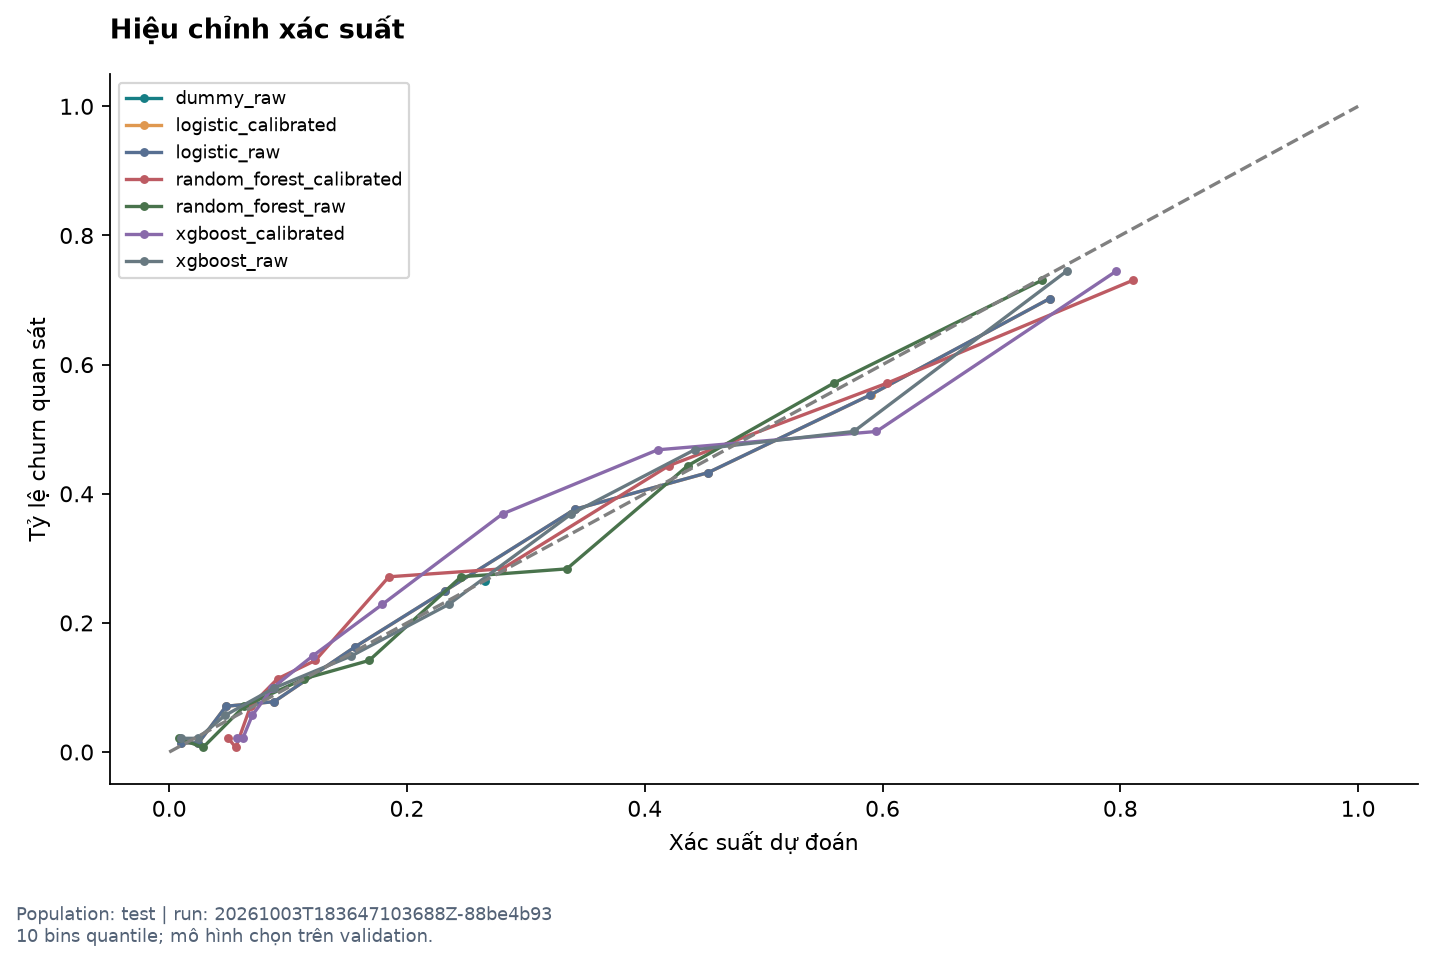

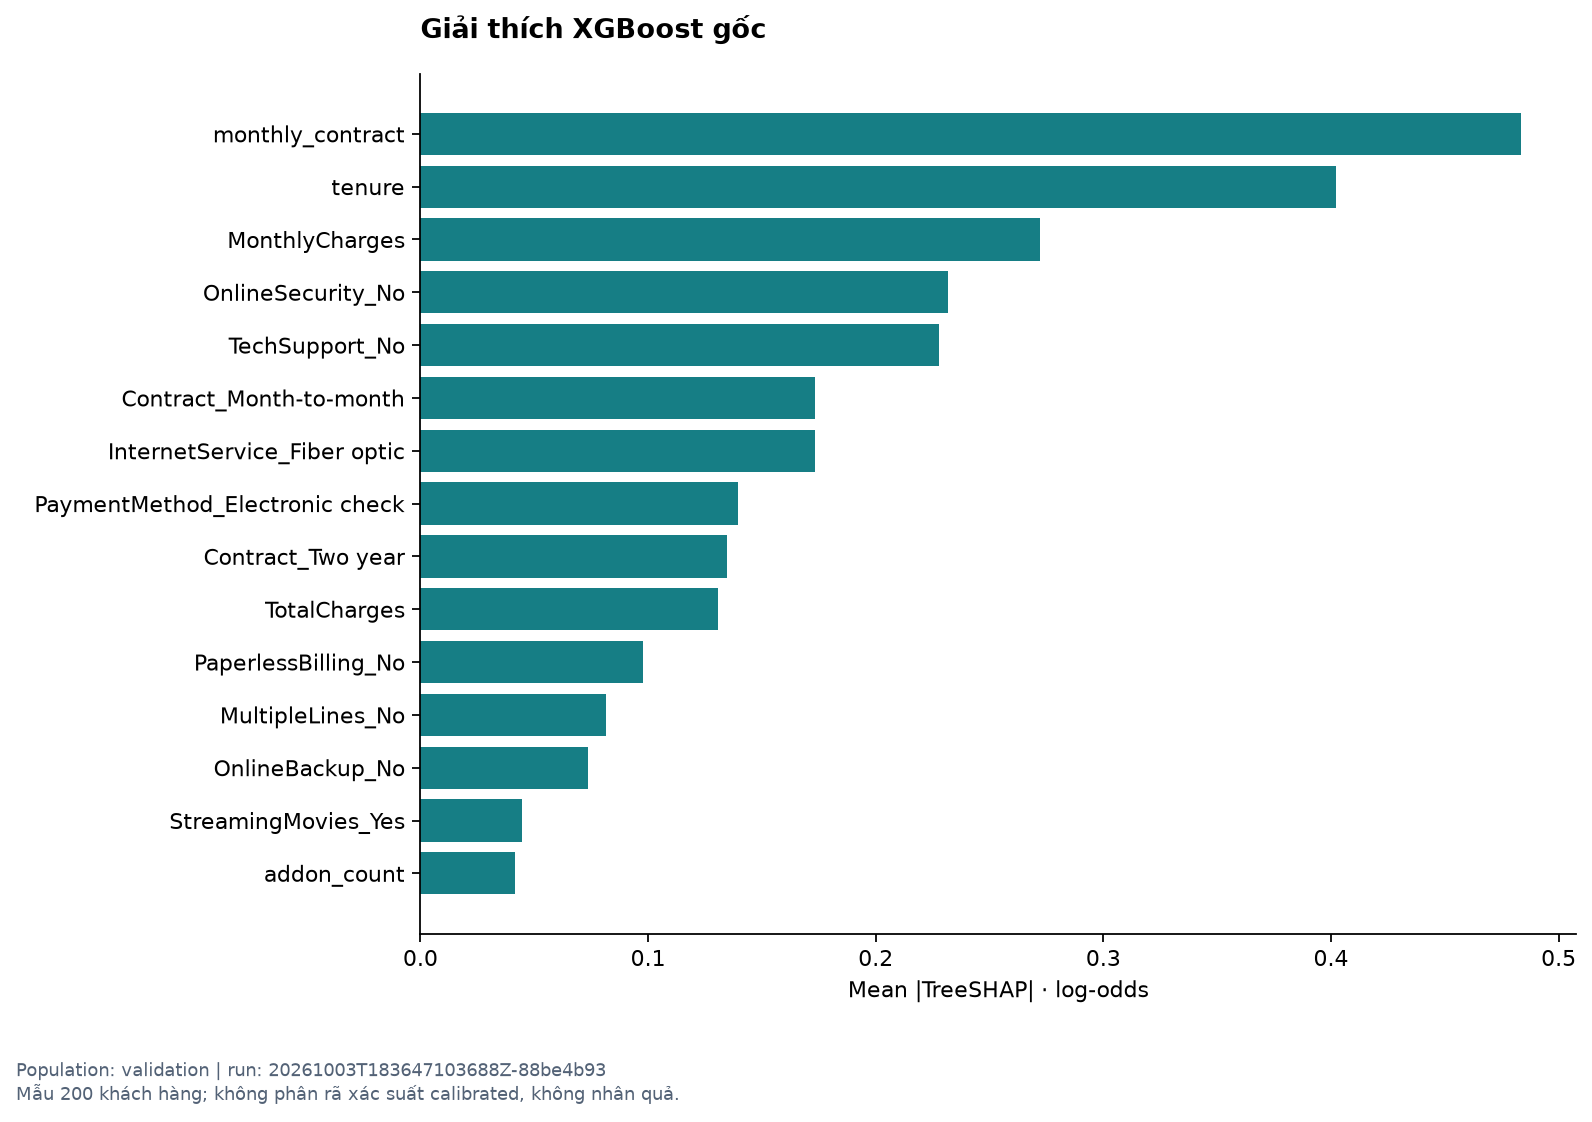

In [4]:
display(Image(filename=str(ROOT / 'reports/figures/calibration.png')))
display(Image(filename=str(ROOT / 'reports/figures/shap_global.png')))